# Step 0 - Sampling (JDsearch, BT4222 Group 9)

Builds the subset of the data that every later notebook uses.

**Inputs** (in `BASE`): `user_behavior_data.txt`, `product_meta_data.txt`

**Outputs** (written to `BASE`):
- `user_subset.parquet` - the sampled users (one row per user, with a `split` column = train / val / test)
- `sampling_before_after.csv` - before/after table for the report
- `figures/` - report figures

**Sampling scheme**
1. Filter: drop sessions where no candidate was clicked, carted or purchased
2. Sample: stratified random sample of users (`SAMPLE_FRAC`), stratified on whether the session has a purchase
3. Truncate: keep each user's most recent `MAX_HIST` history interactions
4. Split: 70/15/15 train/val/test by user, stratified on purchase

Parameters: `SAMPLE_FRAC = 0.5`, `MAX_HIST = 200`, `SEED = 42` (fixed seed, so reruns give the same users).

Note on the save step:
`user_subset.parquet` was first generated during our interim run and is already used by our downstream notebooks (steps 1–4). This notebook documents and reproduces that sampling procedure retrospectively, so the save step checks that the regenerated subset is identical to the existing file before replacing it. This confirms that the results in the later notebooks were computed on exactly the data described here, and an existing file is never overwritten by data that differs.

## 1. Setup

In [7]:
from google.colab import drive
from pathlib import Path
drive.mount("/content/drive")

# >>> SET THIS to the folder that directly contains the two .txt files <<<
BASE = Path("/content/drive/MyDrive/bt4222/JDsearch")

# sanity check - should see user_behavior_data.txt and product_meta_data.txt
!ls "{BASE}"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
figures			   step0_sampling.ipynb  step3b_attention
JDsearch.tar		   step1a_history	 step4_diagnostics
product_chunks		   step1b_query_item	 user_behavior_data.txt
product_meta_data.txt	   step2_baselines	 user_subset.parquet
sampling_before_after.csv  step3a_lambdarank	 user_subset_rerun.parquet


## 2. User-data statistics
All results are stored in the dictionary `R` (X, Y, Z, H, q, ...).

In [8]:
# =============================================================================
# JDsearch - Part 2.1 statistics (Data Overview & Sampling Scheme)
# Requires BASE (set in the setup cell).
# Works from the raw string columns, so it does not need any
# "_parsed" columns (saves a lot of RAM).
# =============================================================================
import gc
import numpy as np
import pandas as pd
from collections import Counter
from itertools import chain
from pathlib import Path

USER_TXT = BASE / "user_behavior_data.txt"

if "user_df" not in globals():
    user_df = pd.read_csv(USER_TXT, sep="\t", dtype=str, low_memory=False)

def split_list(s):
    """Split a '_'-joined list field into a Python list ('' / NaN -> [])."""
    return [] if pd.isna(s) or s == "" else s.split("_")

R = {}   # all results collected here

# -----------------------------------------------------------------------------
# A. USER DATA (user_behavior_data.txt)
# -----------------------------------------------------------------------------
R["users / test sessions"] = len(user_df)

q_counts = user_df["query"].value_counts()
R["distinct test query strings"] = len(q_counts)
R["query strings used by >1 user"] = int((q_counts > 1).sum())

# --- Candidate slates & labels ---
labels = user_df["candidate_label_list"].apply(split_list)
slate_len = labels.str.len()
R["candidate impressions"] = int(slate_len.sum())
R["mean slate length"] = round(slate_len.mean(), 2)
R["median slate length"] = int(slate_len.median())
R["max slate length"] = int(slate_len.max())

label_counts = Counter(chain.from_iterable(labels))
n_imp = R["candidate impressions"]
for lab, name in [("0.0", "no interaction"), ("1.0", "clicks"),
                  ("2.0", "add to cart"), ("3.0", "purchases")]:
    c = label_counts.get(lab, 0)
    R[f"label {lab} ({name})"] = f"{c:,} ({100*c/n_imp:.3f}%)"

has_purchase = labels.apply(lambda l: "3.0" in l)
has_positive = labels.apply(lambda l: any(x != "0.0" for x in l))
R["X: sessions with >=1 purchase"] = int(has_purchase.sum())
R["Y: session-level conversion rate (%)"] = round(100 * has_purchase.mean(), 3)
R["Z: sessions with no positive label"] = int((~has_positive).sum())
R["sessions with >=1 click/cart/purchase (%)"] = round(100 * has_positive.mean(), 2)
del labels; gc.collect()

# --- Historical interactions ---
hist_types = user_df["history_type_list"].apply(split_list)
hist_len = hist_types.str.len()
R["historical interactions"] = int(hist_len.sum())
R["mean history length per user"] = round(hist_len.mean(), 1)
R["median history length per user"] = int(hist_len.median())
R["max history length per user"] = int(hist_len.max())
type_counts = Counter(chain.from_iterable(hist_types))
for t in ["CLICK", "CART", "ORD", "FLW"]:
    c = type_counts.get(t, 0)
    R[f"history {t}"] = f"{c:,} ({100*c/R['historical interactions']:.2f}%)"
R["cold users (<3 history interactions)"] = (
    f"{int((hist_len < 3).sum()):,} ({100*(hist_len < 3).mean():.2f}%)")
del hist_types; gc.collect()

# --- Query-less history actions ---
hist_q = user_df["history_qry_list"].apply(split_list)
n_queryless = sum(q == "-1" for q in chain.from_iterable(hist_q))
R["q: query-less history actions (%)"] = round(100 * n_queryless / R["historical interactions"], 2)
del hist_q; gc.collect()

# --- Duplicate histories ---
R["exact duplicate histories"] = int(user_df["history_wid_list"].duplicated().sum())

# --- Time span (unit assumed = seconds) ---
times = user_df["history_time_list"].apply(lambda s: [float(x) for x in split_list(s)])
all_gaps_max = max(max(t) for t in times if t)
R["max single gap anywhere in history (raw)"] = int(all_gaps_max)
R["max single gap anywhere in history (days, if seconds)"] = round(all_gaps_max / 86400, 1)
last_gap = times.apply(lambda t: t[-1] if t else np.nan)
R["median gap last action -> test query (hours)"] = round(last_gap.median() / 3600, 2)
R["max gap last action -> test query (raw)"] = int(last_gap.max())
R["max gap last action -> test query (days, if seconds)"] = round(last_gap.max() / 86400, 1)
span_days = times.apply(sum) / 86400          # per-user span incl. gap to test query
R["per-user history span days: min"] = round(span_days.min(), 2)
R["per-user history span days: median"] = round(span_days.median(), 1)
R["per-user history span days: mean"] = round(span_days.mean(), 1)
R["per-user history span days: max"] = round(span_days.max(), 1)
del times; gc.collect()

# --- Integrity: len(qry)==len(wid)==len(type)==len(time)-1 ---
def lens_ok(row):
    n = len(split_list(row["history_wid_list"]))
    return (len(split_list(row["history_qry_list"])) == n ==
            len(split_list(row["history_type_list"])) ==
            len(split_list(row["history_time_list"])) - 1)
R["rows passing length check"] = int(user_df.apply(lens_ok, axis=1).sum())

# --- Unique items (stored as ints to save RAM) ---
cand_items = set(map(int, chain.from_iterable(user_df["candidate_wid_list"].apply(split_list))))
hist_items = set(map(int, chain.from_iterable(user_df["history_wid_list"].apply(split_list))))
R["unique items in candidate slates"] = len(cand_items)
R["H: unique items in histories"] = len(hist_items)
R["unique items in candidates OR histories"] = len(cand_items | hist_items)
R["candidate items never seen in any history (%)"] = round(
    100 * len(cand_items - hist_items) / len(cand_items), 2)

In [9]:
for k, v in R.items():
    print(f"{k:<50} {v:,}" if isinstance(v, (int, np.integer)) else f"{k:<50} {v}")

users / test sessions                              173,831
distinct test query strings                        111,556
query strings used by >1 user                      17,437
candidate impressions                              15,510,012
mean slate length                                  89.22
median slate length                                90
max slate length                                   200
label 0.0 (no interaction)                         15,189,116 (97.931%)
label 1.0 (clicks)                                 224,487 (1.447%)
label 2.0 (add to cart)                            75,573 (0.487%)
label 3.0 (purchases)                              20,836 (0.134%)
X: sessions with >=1 purchase                      20,306
Y: session-level conversion rate (%)               11.681
Z: sessions with no positive label                 2,103
sessions with >=1 click/cart/purchase (%)          98.79
historical interactions                            26,667,260
mean history length per user  

## 3. Product-metadata coverage (a, b)
Reads the first column of `product_meta_data.txt` directly.

In [10]:
import csv, gc
import numpy as np
import pandas as pd

PRODUCT_TXT = BASE / "product_meta_data.txt"

# Does the file start with a header row?
with open(PRODUCT_TXT, encoding="utf-8", errors="ignore") as f:
    first_field = f.readline().split("\t")[0].strip().lower()
has_header = first_field == "wid"
print("header row present:", has_header)

# Read ONLY the first column (wid), in chunks, as integers -> low RAM
catalog, n_rows = set(), 0
for chunk in pd.read_csv(PRODUCT_TXT, sep="\t", usecols=[0], dtype=str,
                         header=0 if has_header else None,
                         quoting=csv.QUOTE_NONE, chunksize=2_000_000):
    col = pd.to_numeric(chunk.iloc[:, 0], errors="coerce").dropna().astype(np.int64)
    n_rows += len(chunk)
    catalog.update(col.tolist())
gc.collect()

R["product metadata rows"] = n_rows                     # expect ~12,141,247
R["unique products with metadata"] = len(catalog)
R["a: candidate items with metadata (%)"] = round(100 * len(cand_items & catalog) / len(cand_items), 2)
R["b: history items with metadata (%)"]   = round(100 * len(hist_items & catalog) / len(hist_items), 2)
for k in ["product metadata rows", "unique products with metadata",
          "a: candidate items with metadata (%)", "b: history items with metadata (%)"]:
    print(f"{k:<45} {R[k]:,}" if isinstance(R[k], int) else f"{k:<45} {R[k]}")
del catalog; gc.collect();

header row present: True
product metadata rows                         12,141,247
unique products with metadata                 12,141,247
a: candidate items with metadata (%)          99.32
b: history items with metadata (%)            87.87


## 4. Sampling scheme
Parameters: `SAMPLE_FRAC` (share of users kept after the filter), `MAX_HIST` (history cut-off), `SEED`.
Steps: filter no-positive sessions -> stratified sample of users -> truncate histories -> train/val/test split by user.
**Saves `user_subset.parquet`** (replacing an existing one only if the content is identical).

In [11]:
# SAMPLING SCHEME (parameters to agree with the team)
SAMPLE_FRAC = 0.5    # share of users kept after step 1
MAX_HIST    = 200    # keep the most recent N history interactions per user
SEED        = 42

lab = user_df["candidate_label_list"].apply(split_list)
user_df["has_positive"] = lab.apply(lambda l: any(x != "0.0" for x in l))
user_df["has_purchase"] = lab.apply(lambda l: "3.0" in l)
user_df["hist_len"]     = user_df["history_type_list"].apply(lambda s: len(split_list(s)))
del lab; gc.collect()

# Helps choose MAX_HIST: how much is lost at each cut-off?
tot = user_df["hist_len"].sum()
print("History truncation options:")
for n in [50, 100, 200, 300, 500]:
    kept_users = (user_df["hist_len"] <= n).mean() * 100
    kept_inter = user_df["hist_len"].clip(upper=n).sum() / tot * 100
    print(f"  N={n:<4} users with full history kept: {kept_users:5.1f}%   "
          f"interactions kept: {kept_inter:5.1f}%")

# Step 1 - drop sessions with no positive label (authors' test protocol)
step1 = user_df[user_df["has_positive"]]

# Step 2 - stratified sample of USERS (keeps each slate + history intact and
#          keeps the purchase-session share identical to the full data)
subset = (step1.groupby("has_purchase", group_keys=False)
               .sample(frac=SAMPLE_FRAC, random_state=SEED)
               .copy())

# Step 3 - truncate histories to the most recent MAX_HIST interactions
def truncate(df, n):
    df = df.copy()
    for c in ["history_qry_list", "history_wid_list", "history_type_list"]:
        df[c] = df[c].apply(lambda s: "_".join(split_list(s)[-n:]))
    df["history_time_list"] = df["history_time_list"].apply(      # 1 longer
        lambda s: "_".join(split_list(s)[-(n + 1):]))
    return df
subset = truncate(subset, MAX_HIST)

# Step 4 - user-level train/val/test split (70/15/15), stratified on purchase
subset = subset.sample(frac=1, random_state=SEED)
subset["split"] = "train"
for flag, g in subset.groupby("has_purchase"):
    n = len(g)
    subset.loc[g.index[int(0.70 * n):int(0.85 * n)], "split"] = "val"
    subset.loc[g.index[int(0.85 * n):], "split"] = "test"

def stats(df):
    lab = df["candidate_label_list"].apply(split_list)
    c = Counter(chain.from_iterable(lab))
    n = sum(c.values())
    pos = n - c.get("0.0", 0)
    return pd.Series({
        "users / sessions": len(df),
        "candidate impressions": n,
        "clicks (label 1)": c.get("1.0", 0),
        "add to cart (label 2)": c.get("2.0", 0),
        "purchases (label 3)": c.get("3.0", 0),
        "item-level purchase rate (%)": round(100 * c.get("3.0", 0) / n, 3),
        "item-level any-interaction rate (%)": round(100 * pos / n, 3),
        "session-level conversion rate (%)": round(100 * lab.apply(lambda l: "3.0" in l).mean(), 2),
        "historical interactions": int(df["history_type_list"].apply(split_list).str.len().sum()),
    }, dtype=object)

before_after = pd.concat({"Full dataset": stats(user_df),
                          "After step 1 (drop no-positive)": stats(step1),
                          "Final subset": stats(subset)}, axis=1)
print(before_after.to_string())
print("\nSplit sizes:\n", subset["split"].value_counts().to_string())
print("Session conversion by split (%):\n",
      (subset.groupby("split")["has_purchase"].mean() * 100).round(2).to_string())

# ---- Save the subset for the team --------------------------------------------
# Written to a temporary file first. An existing user_subset.parquet is only
# replaced if the new data is identical to it; otherwise it is left untouched
# and the new data goes to user_subset_rerun.parquet.
import os
new    = subset.drop(columns=["has_positive", "hist_len"]).reset_index(drop=True)
TARGET = BASE / "user_subset.parquet"
TMP    = BASE / "user_subset.tmp.parquet"
new.to_parquet(TMP, index=False)
before_after.to_csv(BASE / "sampling_before_after.csv")

safe = True
if TARGET.exists():
    old = pd.read_parquet(TARGET)
    same_cols = list(old.columns) == list(new.columns)
    print("same columns:", same_cols, "| shape old/new:", old.shape, new.shape)
    safe = bool(same_cols and old.shape == new.shape and old.equals(new))
    print("identical to existing user_subset.parquet (incl. row order):", safe)
    del old
if safe:
    os.replace(TMP, TARGET)
    print("Saved:", TARGET)
else:
    os.replace(TMP, BASE / "user_subset_rerun.parquet")
    print("WARNING: differs from the existing user_subset.parquet, which was left untouched.")
    print("New data saved as user_subset_rerun.parquet - check the parameters before replacing the team's file.")

History truncation options:
  N=50   users with full history kept:  38.0%   interactions kept:  25.7%
  N=100  users with full history kept:  57.3%   interactions kept:  42.6%
  N=200  users with full history kept:  76.7%   interactions kept:  63.3%
  N=300  users with full history kept:  86.0%   interactions kept:  75.1%
  N=500  users with full history kept:  94.0%   interactions kept:  87.4%
                                    Full dataset After step 1 (drop no-positive) Final subset
users / sessions                          173831                          171728        85864
candidate impressions                   15510012                        15348717      7665446
clicks (label 1)                          224487                          224487       112099
add to cart (label 2)                      75573                           75573        37708
purchases (label 3)                        20836                           20836        10428
item-level purchase rate (%)          

## 5. Report figures
Saved as PNGs into `BASE/figures`.

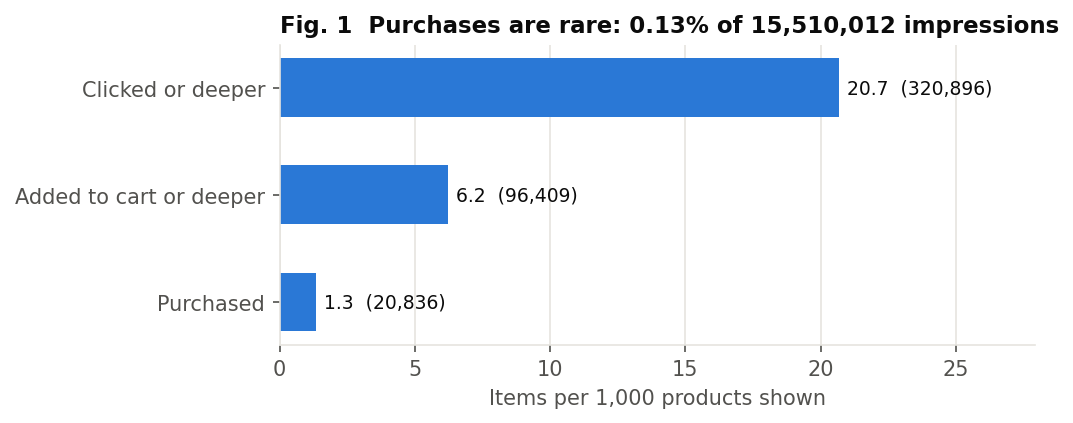

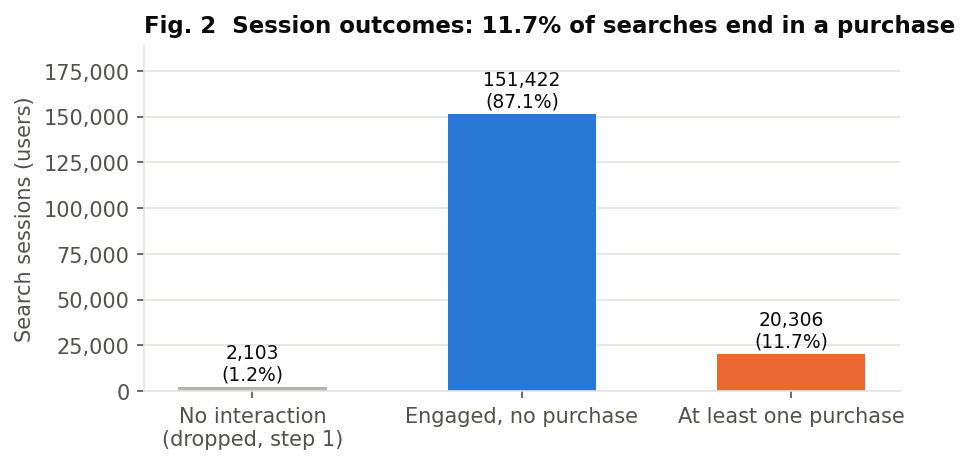

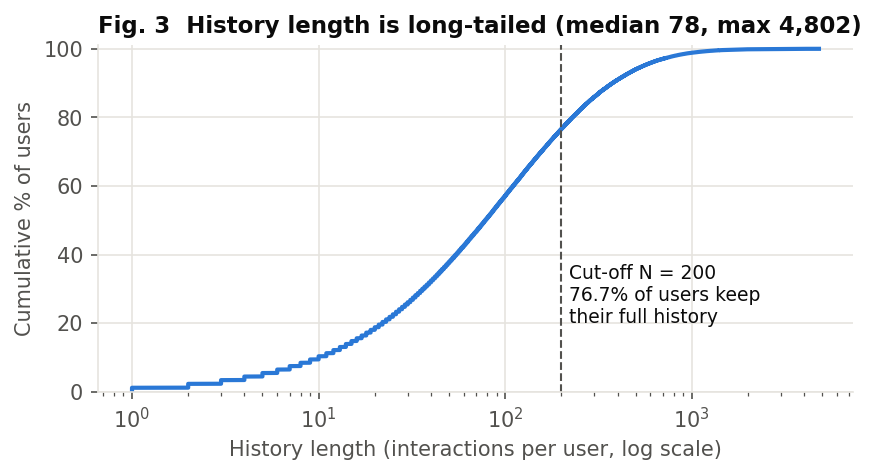

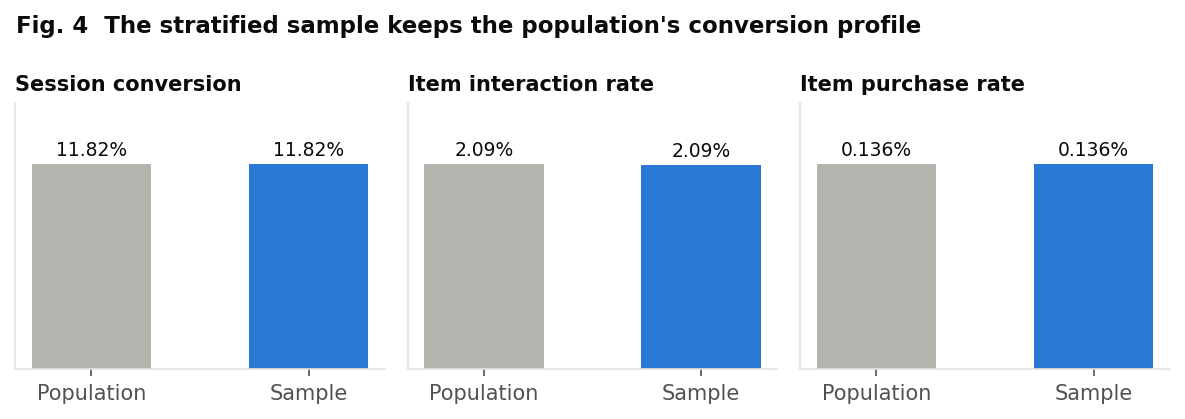

In [12]:
# Report figures (saved as PNG into BASE/figures)
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

FIG_DIR = BASE / "figures"; FIG_DIR.mkdir(exist_ok=True)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e4df"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.dpi": 150, "savefig.bbox": "tight",
})

# ---- Figure 1: engagement funnel per 1,000 products shown
lc = Counter(chain.from_iterable(user_df["candidate_label_list"].apply(split_list)))
n_imp = sum(lc.values())
ge_click = lc["1.0"] + lc["2.0"] + lc["3.0"]
ge_cart  = lc["2.0"] + lc["3.0"]
funnel = {"Clicked or deeper": ge_click, "Added to cart or deeper": ge_cart, "Purchased": lc["3.0"]}
vals = [v / n_imp * 1000 for v in funnel.values()]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh(list(funnel)[::-1], vals[::-1], color=BLUE, height=0.55)
for i, (v, raw) in enumerate(zip(vals[::-1], list(funnel.values())[::-1])):
    ax.text(v + 0.3, i, f"{v:.1f}  ({raw:,})", va="center", color=INK, fontsize=9)
ax.set_xlabel("Items per 1,000 products shown")
ax.set_xlim(0, max(vals) * 1.35); ax.grid(axis="y", visible=False)
ax.set_title(f"Fig. 1  Purchases are rare: {lc['3.0']/n_imp:.2%} of {n_imp:,} impressions")
fig.savefig(FIG_DIR / "fig1_funnel.png"); plt.show()

# ---- Figure 2: what happens to each search session
n_none = int((~user_df["has_positive"]).sum())
n_pur  = int(user_df["has_purchase"].sum())
n_eng  = len(user_df) - n_none - n_pur
cats = ["No interaction\n(dropped, step 1)", "Engaged, no purchase", "At least one purchase"]
cnts = [n_none, n_eng, n_pur]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(cats, cnts, color=[GREY, BLUE, ORANGE], width=0.55)
for i, c in enumerate(cnts):
    ax.text(i, c + len(user_df) * 0.01, f"{c:,}\n({c/len(user_df):.1%})",
            ha="center", va="bottom", color=INK, fontsize=9)
ax.set_ylabel("Search sessions (users)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_ylim(0, max(cnts) * 1.25); ax.grid(axis="x", visible=False)
ax.set_title(f"Fig. 2  Session outcomes: {n_pur/len(user_df):.1%} of searches end in a purchase")
fig.savefig(FIG_DIR / "fig2_session_outcomes.png"); plt.show()

# ---- Figure 3: history length distribution and the truncation cut-off
hl = np.sort(user_df["hist_len"].values)
cdf = np.arange(1, len(hl) + 1) / len(hl) * 100
pct_full = (hl <= MAX_HIST).mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(np.maximum(hl, 1), cdf, color=BLUE, lw=2)
ax.axvline(MAX_HIST, color=INK2, lw=1, ls="--")
ax.text(MAX_HIST * 1.1, 20, f"Cut-off N = {MAX_HIST}\n{pct_full:.1f}% of users keep\ntheir full history",
        color=INK, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("History length (interactions per user, log scale)")
ax.set_ylabel("Cumulative % of users"); ax.set_ylim(0, 101)
ax.set_title(f"Fig. 3  History length is long-tailed (median {int(np.median(hl))}, max {hl.max():,})")
fig.savefig(FIG_DIR / "fig3_history_length.png"); plt.show()

# ---- Figure 4: sample preserves the conversion profile (small multiples)
metrics = [("session-level conversion rate (%)", "Session conversion"),
           ("item-level any-interaction rate (%)", "Item interaction rate"),
           ("item-level purchase rate (%)", "Item purchase rate")]
cols = ["After step 1 (drop no-positive)", "Final subset"]
fig, axes = plt.subplots(1, 3, figsize=(8, 2.8))
for ax, (m, title) in zip(axes, metrics):
    v = [before_after.loc[m, c] for c in cols]
    ax.bar(["Population", "Sample"], v, color=[GREY, BLUE], width=0.55)
    for i, x in enumerate(v):
        ax.text(i, x * 1.02, f"{x:.2f}%" if x >= 1 else f"{x:.3f}%",
                ha="center", va="bottom", color=INK, fontsize=9)
    ax.set_ylim(0, max(v) * 1.3); ax.set_title(title, fontsize=10)
    ax.grid(axis="x", visible=False); ax.set_yticks([])
fig.suptitle("Fig. 4  The stratified sample keeps the population's conversion profile",
             x=0.02, ha="left", fontweight="bold", color=INK, fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_sample_vs_population.png"); plt.show()